# Dar_042: lunar science-based environmental indicators

Reuses Dar_020 matched candidate profiles and the checked REDMoon reference scenarios. Sky openness is a geometric primary-particle indicator, not dose. Sun visibility is a UV opportunity proxy, not irradiance; it must not be counted twice with sunlight as independent weighted evidence. Plasma regimes are sourced references, not local voltages. Missing response/limits stay Unknown. [Sources and model contract](../../../research/lunar_science_models.json).

In [1]:
from pathlib import Path
import sys, json
root = Path.cwd().resolve()
while not (root / "outline.md").is_file():
    if root == root.parent: raise RuntimeError("Run inside the repository")
    root = root.parent
sys.path.insert(0, str(root))
sys.path.insert(0, str(root / "darrel stuff/EDA"))
from lunar_science_eda import execute
folder, findings = execute(sample=False)
print(folder)

{
  "sample": false,
  "candidates": 21,
  "sky_proxy_available": 21,
  "uv_proxy_available": 21,
  "complete_thermal_candidates": 5,
  "sky_medians_above_2pi": 18,
  "reference_scenarios": 96,
  "charging_reference_regimes": 3,
  "candidate_dose_or_voltage_invented": false,
  "operational_safety_limits_adopted": false,
  "holds": [
    "No whole-component physical support or uncertainty calibration inferred",
    "UV proxy is not UV irradiance or dose",
    "Sky openness is not transported radiation dose",
    "Plasma response and all operational conclusions remain Unknown"
  ]
}
C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\processed\analysis\lunar_science_indicators\20261109T143200137069Z_e4281e


,candidate_id,sky_visible_fraction_4pi,uv_sun_visibility_opportunity_proxy,thermal_phase_median_span_K
0,A3CLR22_10_Leibnitz_Beta_Plateau:diagnostic_co...,0.508102,0.52364,NaN
1,A3CLR22_10_Leibnitz_Beta_Plateau:diagnostic_co...,0.508261,0.54260,NaN
2,A3CLR22_10_Leibnitz_Beta_Plateau:diagnostic_co...,0.501402,0.51422,NaN
3,A3CLR22_11_Malapert_Massif:diagnostic_componen...,0.507577,0.53466,156.312740
4,A3CLR22_11_Malapert_Massif:diagnostic_componen...,0.503479,0.53088,177.129112
5,A3CLR22_11_Malapert_Massif:diagnostic_componen...,0.508436,0.54594,170.077390
6,A3CLR22_12_deGerlache_Kocher_Massif:diagnostic...,0.507084,0.53896,NaN
7,A3CLR22_12_deGerlache_Kocher_Massif:diagnostic...,0.508102,0.51552,NaN
8,A3CLR22_12_deGerlache_Kocher_Massif:diagnostic...,0.503328,0.57856,NaN
9,A3CLR22_2_Haworth:diagnostic_component_00014,0.504967,0.53240,169.893570


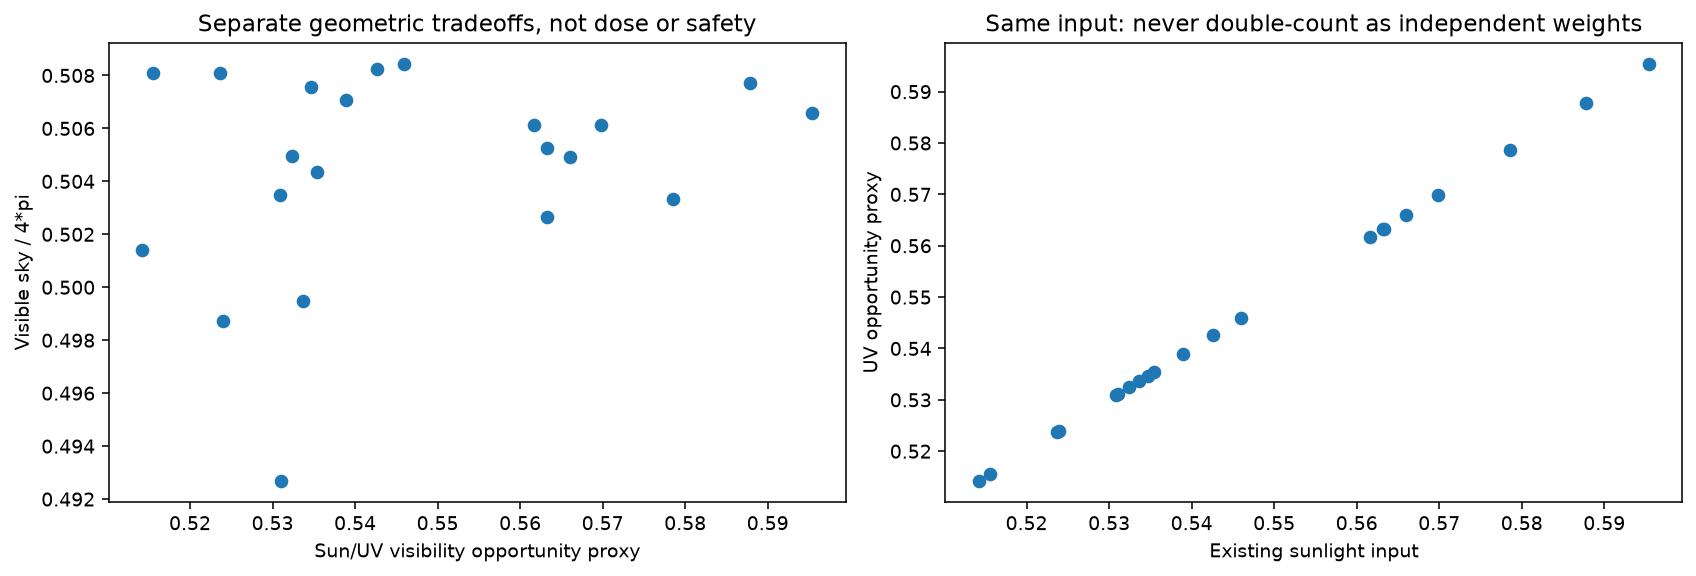

In [2]:
import pandas as pd
from IPython.display import display, Image
profiles = pd.read_csv(folder / "candidate_science_profiles.csv")
indicators = pd.read_csv(folder / "candidate_science_indicators.csv")
assert indicators.candidate_operational_conclusion.eq("Unknown").all()
assert profiles.sky_visible_fraction_4pi.between(0,1).all()
assert profiles.uv_sun_visibility_opportunity_proxy.equals(profiles.solar_opportunity_fraction_median)
assert not any("dose" in c.lower() or "voltage" in c.lower() for c in profiles.columns)
display(profiles[["candidate_id", "sky_visible_fraction_4pi", "uv_sun_visibility_opportunity_proxy", "thermal_phase_median_span_K"]])
display(Image(filename=str(folder / "science_proxy_tradeoffs.png")))

In [3]:
reference = pd.read_csv(folder / "radiation_reference_scenarios.csv")
assert "candidate_id" not in reference
assert reference.evidence_basis.eq("Reference").all()
display(reference.head(12))
display(pd.read_csv(folder / "plasma_reference_cases.csv"))
print("Scenarios are not assigned as measured site dose or operational passes.")

,al_g_cm2,solar_scenario,particles,depth_cm,effective_dose_cSv_year,illustrative_days,reference_mSv,basis,evidence_basis,source_ids,role
0,1,Smax2015,all,0.0,22.4167,1,0.613736,published scenario; assumed steady annual rate...,Reference,REDMOON,common_what_if_library_NOT_site_ranking_or_limit
1,1,Smax2015,all,10.0,20.8979,1,0.572153,published scenario; assumed steady annual rate...,Reference,REDMOON,common_what_if_library_NOT_site_ranking_or_limit
2,1,Smax2015,all,100.0,17.6342,1,0.482798,published scenario; assumed steady annual rate...,Reference,REDMOON,common_what_if_library_NOT_site_ranking_or_limit
3,1,Smin2019,all,0.0,41.1292,1,1.126056,published scenario; assumed steady annual rate...,Reference,REDMOON,common_what_if_library_NOT_site_ranking_or_limit
4,1,Smin2019,all,10.0,34.9010,1,0.955537,published scenario; assumed steady annual rate...,Reference,REDMOON,common_what_if_library_NOT_site_ranking_or_limit
5,1,Smin2019,all,100.0,24.9827,1,0.683989,published scenario; assumed steady annual rate...,Reference,REDMOON,common_what_if_library_NOT_site_ranking_or_limit
6,10,Smax2015,all,0.0,20.0785,1,0.549719,published scenario; assumed steady annual rate...,Reference,REDMOON,common_what_if_library_NOT_site_ranking_or_limit
7,10,Smax2015,all,10.0,20.5370,1,0.562272,published scenario; assumed steady annual rate...,Reference,REDMOON,common_what_if_library_NOT_site_ranking_or_limit
8,10,Smax2015,all,100.0,17.1775,1,0.470294,published scenario; assumed steady annual rate...,Reference,REDMOON,common_what_if_library_NOT_site_ranking_or_limit
9,10,Smin2019,all,0.0,34.9497,1,0.956871,published scenario; assumed steady annual rate...,Reference,REDMOON,common_what_if_library_NOT_site_ranking_or_limit


,regime,mechanism,source_ids,inference_limit,basis,local_surface_potential_V,operational_status
0,sunlit_surface,Solar photoemission and collection of plasma e...,CHARGING_MODEL; UV_SCIENCE,Mean solar visibility does not determine volta...,Reference,NaN,Unknown
1,near_terminator_or_shadow_boundary,Changing illumination and plasma-current balance,CHARGING_MODEL,Source model domain and electron/material inpu...,Reference,NaN,Unknown
2,dark_plasma_poor_polar_terrain,Limited charge dissipation and possible triboe...,PSR_CHARGING,Dark or plasma-poor does not imply electricall...,Reference,NaN,Unknown


Scenarios are not assigned as measured site dose or operational passes.
